In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shristisaha903/dataset6/advanced_features_full_v2.csv


In [4]:
!pip install -q optuna

In [5]:
import pandas as pd
import numpy as np
import optuna
import time
import joblib
import os
import warnings
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

warnings.filterwarnings("ignore")

# 1. LOAD DATA
DATA_PATH = "/kaggle/input/datasets/shristisaha903/dataset6/advanced_features_full_v2.csv" 
df = pd.read_csv(DATA_PATH)
exclude_cols = ['target', 'point_idx', 'trip_id', 'arc_id']
features = [c for c in df.columns if c not in exclude_cols]
X = df[features]
y = df["target"]

# 2. GROUP SPLIT
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, val_idx = next(gss.split(X, y, groups=df['trip_id']))

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]
y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

# Scale ONCE
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# 3. FAST OBJECTIVE FUNCTION (L2 ONLY)
def objective(trial):
    param = {
        'C': trial.suggest_float('C', 1e-3, 10.0, log=True),
        'penalty': 'l2',      # FORCED L2 to prevent 5-minute delays
        'solver': 'liblinear', 
        'class_weight': 'balanced',
        'max_iter': 100, 
        'random_state': 42
    }
    model = LogisticRegression(**param)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_val_scaled)
    return f1_score(y_val, y_pred, average='macro')

# 4. RUN OPTIMIZATION
print("\nStarting FASTEST L2-Only Bayesian Optimization (10 trials)...")
start_time = time.time()

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=10) 

print(f"\nOptimization completed in {time.time() - start_time:.2f} seconds!")
print(f"Best F1-Score: {study.best_value:.4f}")
print(f"Best Hyperparameters: {study.best_params}")

results_df = study.trials_dataframe()
results_df.to_csv("/kaggle/working/optuna_lr_results.csv", index=False)

[I 2026-11-18 14:07:02,023] A new study created in memory with name: no-name-b0e42343-8875-4c8e-9bbb-cd3d28c316f8



Starting FASTEST L2-Only Bayesian Optimization (10 trials)...


[I 2026-11-18 14:07:14,694] Trial 0 finished with value: 0.7742284771173541 and parameters: {'C': 2.8290753324367452}. Best is trial 0 with value: 0.7742284771173541.
[I 2026-11-18 14:07:19,487] Trial 1 finished with value: 0.7725035465577321 and parameters: {'C': 0.0011651330333496475}. Best is trial 0 with value: 0.7742284771173541.
[I 2026-11-18 14:07:26,774] Trial 2 finished with value: 0.7737127284603083 and parameters: {'C': 0.014176806684850121}. Best is trial 0 with value: 0.7742284771173541.
[I 2026-11-18 14:07:47,147] Trial 3 finished with value: 0.7743380750865598 and parameters: {'C': 0.22908450556573515}. Best is trial 3 with value: 0.7743380750865598.
[I 2026-11-18 14:08:12,194] Trial 4 finished with value: 0.7742663983199409 and parameters: {'C': 0.947000157460248}. Best is trial 3 with value: 0.7743380750865598.
[I 2026-11-18 14:08:17,399] Trial 5 finished with value: 0.772713718714239 and parameters: {'C': 0.0019485862637687549}. Best is trial 3 with value: 0.774338075


Optimization completed in 129.14 seconds!
Best F1-Score: 0.7743
Best Hyperparameters: {'C': 0.22908450556573515}


In [6]:
import os
import joblib
from sklearn.metrics import accuracy_score, log_loss
from sklearn.linear_model import LogisticRegression

print("\nTraining final Tuned Logistic Regression...")

# 1. Retrain the model with the best hyperparameters found by Optuna
best_model = LogisticRegression(
    **study.best_params, 
    class_weight='balanced', 
    max_iter=100, 
    solver='liblinear',
    random_state=42
)
best_model.fit(X_train_scaled, y_train)

# 2. Evaluate on validation set
y_pred_tuned = best_model.predict(X_val_scaled)
y_prob_tuned = best_model.predict_proba(X_val_scaled)[:, 1]

acc_tuned = accuracy_score(y_val, y_pred_tuned)
f1_tuned = f1_score(y_val, y_pred_tuned)
ll_tuned = log_loss(y_val, y_prob_tuned)

# 3. Top-1 Accuracy (Observation Level)
# We group by point_idx and check if the max-probability candidate is correct
val_df = X_val.copy()
val_df["point_idx"] = df.loc[val_idx, "point_idx"]
val_df["target"] = y_val.values
val_df["prob"] = y_prob_tuned
val_df["pred"] = y_pred_tuned

top1_preds = val_df.loc[val_df.groupby("point_idx")["prob"].idxmax()]
top1_acc = (top1_preds["pred"] == top1_preds["target"]).mean()

# 4. Print Final Results
print("\n=== TUNED LOGISTIC REGRESSION RESULTS ===")
print(f"Accuracy:  {acc_tuned:.4f}")
print(f"F1-Score:  {f1_tuned:.4f}")
print(f"Log Loss:  {ll_tuned:.4f}")
print(f"Top-1 Acc: {top1_acc:.4f}")

# 5. Save both the model and the scaler for the API/HMM
os.makedirs("/kaggle/working/artifacts", exist_ok=True)

model_path = "/kaggle/working/artifacts/logistic_regression_tuned_v2.pkl"
scaler_path = "/kaggle/working/artifacts/scaler_v2.pkl"

joblib.dump(best_model, model_path)
joblib.dump(scaler, scaler_path)

print(f"\nModel saved to: {model_path}")
print(f"Scaler saved to: {scaler_path}")
print("You can now download these files from the Output tab.")


Training final Tuned Logistic Regression...

=== TUNED LOGISTIC REGRESSION RESULTS ===
Accuracy:  0.7744
F1-Score:  0.7787
Log Loss:  0.5274
Top-1 Acc: 0.7576

Model saved to: /kaggle/working/artifacts/logistic_regression_tuned_v2.pkl
Scaler saved to: /kaggle/working/artifacts/scaler_v2.pkl
You can now download these files from the Output tab.


Loading results from: /kaggle/working/optuna_lr_results.csv


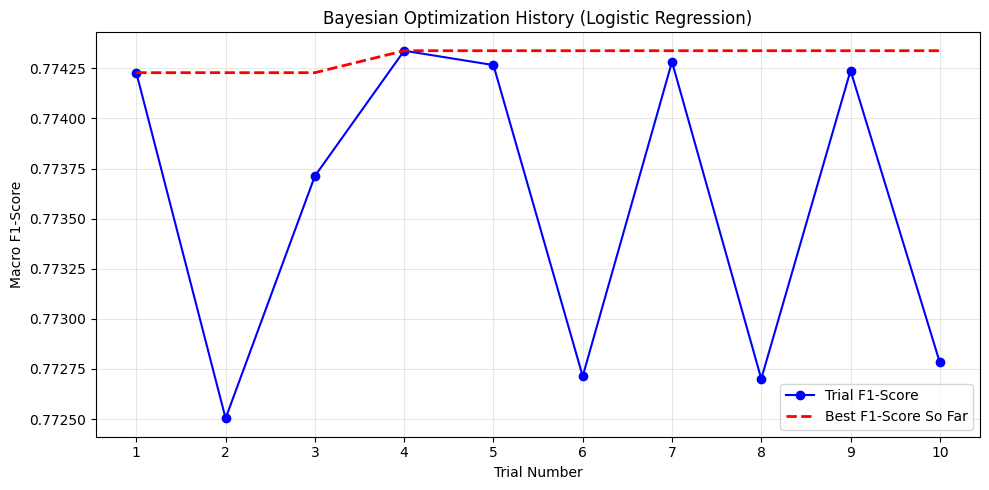

Best F1-Score: 0.7743


In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import os

# Try both locations (working dir and artifacts folder)
csv_path = "/kaggle/working/optuna_lr_results.csv"
if not os.path.exists(csv_path):
    csv_path = "/kaggle/working/artifacts/optuna_lr_results.csv"

print(f"Loading results from: {csv_path}")
results_df = pd.read_csv(csv_path)

# Extract trials and scores
trials = results_df.index + 1
scores = results_df['value']

# Create the plot
plt.figure(figsize=(10, 5))
plt.plot(trials, scores, marker='o', linestyle='-', color='b', label='Trial F1-Score')

# Best so far
best_so_far = scores.cummax()
plt.plot(trials, best_so_far, linestyle='--', color='r', linewidth=2, label='Best F1-Score So Far')

plt.title('Bayesian Optimization History (Logistic Regression)')
plt.xlabel('Trial Number')
plt.ylabel('Macro F1-Score')
plt.xticks(trials)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("/kaggle/working/optuna_history.png", dpi=150)
plt.show()

print(f"Best F1-Score: {scores.max():.4f}")